# Vision Transformers on Wildlife Camera Traps: Do They Generalise to Unseen Locations?

**MAAI 901 Applied Vision Transformer Report** · Aravind

**Research question (from the Week 4 proposal):** does a fine-tuned Vision Transformer generalise better than a comparable CNN from seen to unseen camera locations, and are its errors at unseen locations associated with attention placed outside the animal?

* **H1 (primary):** ViT-B/16 shows a smaller *relative generalisation gap* than ResNet-50, where gap = (macro F1 on `cis_test` − macro F1 on `trans_test`) / macro F1 on `cis_test`. Tested with a paired bootstrap confidence interval.
* **H0:** no difference in relative gap.
* **H2 (secondary):** on unseen-location images, the share of ViT attention-rollout mass inside the animal's bounding box is lower for misclassified images than for correct ones. Tested with a Mann-Whitney U test.

**Dataset:** Caltech Camera Traps 20 (CCT20, Beery et al., ECCV 2018), from [LILA BC](https://lila.science/datasets/caltech-camera-traps). About 57k images from 20 camera locations in the American Southwest.

| Split | Locations | Images | Used for |
| --- | --- | --- | --- |
| `train` | 10 seen | 13.5k | training |
| `cis_val` | same 10 | 3.5k | model selection (early stopping) |
| `cis_test` | same 10 | 15.8k | **in-distribution** test |
| `trans_test` | 9 unseen | 23.3k | **out-of-distribution** test (the key result) |
| `trans_val` | 1 unseen | 1.7k | not used, to keep unseen locations unseen |

**Experiments**
1. ResNet-50 fine-tuned (CNN reference for H1, links to Week 3)
2. ViT-B/16 fine-tuned (main model)
3. CLIP ViT-B/16 zero-shot (secondary reference: no task training)
4. *Optional:* ResNet-50 pretrained on ImageNet-21k (BiT), to control the pretraining-data confound named in the proposal

**How to run:** Google Colab, *Runtime → Change runtime type → T4 GPU*, then *Run all*. The first run downloads about 6.5 GB. Budget roughly 2-3 hours of GPU time for all three experiments; each experiment saves its results, so you can run them in separate sessions.

## 1. Setup

In [4]:
!pip install -q transformers timm scikit-learn seaborn scipy

In [5]:
import os, json, random, time, tarfile, urllib.request
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms as T
from scipy.stats import mannwhitneyu
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import ViTForImageClassification, CLIPModel, CLIPProcessor, get_cosine_schedule_with_warmup

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| torch', torch.__version__)

Device: cuda | torch 2.11.0+cu130


In [8]:
# ---- Configuration: change these, not the code below ----
DATA_DIR    = '/content/cct20'          # where data is downloaded and extracted
OUT_DIR     = '/content/outputs'        # checkpoints, figures, results CSVs
IMG_SIZE    = 224
BATCH_SIZE  = 64
NUM_WORKERS = 2
EPOCHS      = {'resnet50': 10, 'vit': 10}   # both were still improving on cis_val at 6 / 5 epochs in the first run
LR          = {'resnet50': 3e-4, 'vit': 3e-5}
WEIGHT_DECAY = 0.05
# Classes dropped: 'empty' has no training images in CCT20; 'badger' and 'fox' have fewer than 10.
DROP_CLASSES = {'empty', 'badger', 'fox'}
# Set to an int (e.g. 4000) to train on a random subset if you are short of time.
TRAIN_SUBSET = None
SMOKE_TEST  = False   # True = tiny run to check the pipeline end to end
RUN_BIT_CONTROL = False   # optional 4th experiment: ResNet-50 pretrained on ImageNet-21k
N_BOOT      = 1000    # bootstrap resamples for H1
H2_MAX_IMAGES = 3000  # unseen-location images used for the H2 attention analysis

VIT_CKPT  = 'google/vit-base-patch16-224-in21k'
CLIP_CKPT = 'openai/clip-vit-base-patch16'
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

## 2. Download CCT20
Images (6.5 GB, already downsized to max 1024 px) and the ECCV 2018 split files. Skips anything already downloaded.

*If you use Google Drive to keep data between sessions, set `DATA_DIR` to a Drive folder. Extracting there is slow, so copying the tar to Drive and extracting to `/content` each session is usually faster.*

In [9]:
BASE = 'https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/'
FILES = {'eccv_18_annotations.tar.gz': 'eccv_18_annotation_files',
         'eccv_18_all_images_sm.tar.gz': 'eccv_18_all_images_sm'}
for fname, folder in FILES.items():
    if os.path.isdir(os.path.join(DATA_DIR, folder)):
        print('Already extracted:', folder); continue
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print('Downloading', fname, '...'); t = time.time()
        urllib.request.urlretrieve(BASE + fname, path)
        print(f'  done in {time.time()-t:.0f}s')
    print('Extracting', fname, '...')
    with tarfile.open(path) as tf: tf.extractall(DATA_DIR)
    os.remove(path)
ANN_DIR = os.path.join(DATA_DIR, 'eccv_18_annotation_files')
IMG_DIR = os.path.join(DATA_DIR, 'eccv_18_all_images_sm')
print(len(os.listdir(IMG_DIR)), 'images')

  done in 0s
Extracting eccv_18_annotations.tar.gz ...


/tmp/ipykernel_449/148409916.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(path) as tf: tf.extractall(DATA_DIR)


  done in 79s
Extracting eccv_18_all_images_sm.tar.gz ...
57864 images


## 3. Build the dataset table
Annotations are in COCO Camera Traps format. A few hundred images contain more than one species; we keep only single-species images so each image has one label.

In [10]:
SPLITS = ['train', 'cis_val', 'cis_test', 'trans_test']
rows = []
for split in SPLITS:
    d = json.load(open(os.path.join(ANN_DIR, f'{split}_annotations.json')))
    cats = {c['id']: c['name'] for c in d['categories']}
    labels, boxes = {}, {}
    for a in d['annotations']:
        labels.setdefault(a['image_id'], set()).add(cats[a['category_id']])
        if a.get('bbox'): boxes.setdefault(a['image_id'], []).append(a['bbox'])
    for im in d['images']:
        labs = labels.get(im['id'], set())
        if len(labs) != 1: continue
        rows.append({'split': split, 'file': im['file_name'], 'label': next(iter(labs)),
                     'location': im['location'], 'seq_id': im.get('seq_id'), 'date': im.get('date_captured'),
                     # boxes are [x, y, w, h] in the ORIGINAL resolution (orig_w x orig_h); the downloaded images are smaller
                     'boxes': boxes.get(im['id'], []), 'orig_w': im['width'], 'orig_h': im['height']})
df = pd.DataFrame(rows)
df = df[~df.label.isin(DROP_CLASSES)]
df = df[df.file.map(lambda f: os.path.exists(os.path.join(IMG_DIR, f)))].reset_index(drop=True)

if TRAIN_SUBSET:
    keep = df[df.split == 'train'].sample(TRAIN_SUBSET, random_state=SEED).index
    df = df[(df.split != 'train') | df.index.isin(keep)].reset_index(drop=True)
if SMOKE_TEST:
    df = pd.concat([g.sample(min(len(g), 48), random_state=SEED) for _, g in df.groupby('split')]).reset_index(drop=True)

CLASSES = sorted(df[df.split == 'train'].label.unique())
C2I = {c: i for i, c in enumerate(CLASSES)}
df['y'] = df.label.map(C2I)
df = df[df.y.notna()].reset_index(drop=True); df['y'] = df.y.astype(int)
print(len(CLASSES), 'classes:', CLASSES)
df.groupby('split').agg(images=('file', 'size'), locations=('location', 'nunique'))

13 classes: ['bird', 'bobcat', 'car', 'cat', 'coyote', 'deer', 'dog', 'opossum', 'rabbit', 'raccoon', 'rodent', 'skunk', 'squirrel']


,images,locations
split,,
cis_test,14640,10
cis_val,2488,10
train,13538,10
trans_test,21473,9


## 4. Exploratory analysis

split,train,cis_val,cis_test,trans_test
label,,,,
opossum,2726,490,4524,5504
rabbit,2443,493,1757,843
coyote,1403,285,1326,2249
cat,1287,192,1632,1418
squirrel,1249,222,659,1050
raccoon,1027,169,1047,5469
dog,820,139,845,888
bobcat,785,154,897,2329
car,668,41,791,1113


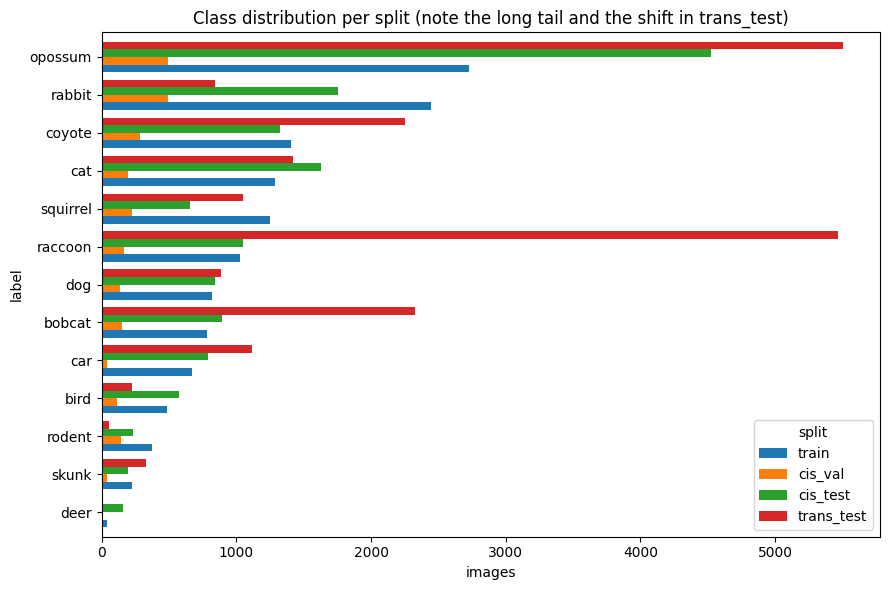

In [11]:
counts = df.pivot_table(index='label', columns='split', values='file', aggfunc='size', fill_value=0)[SPLITS]
display(counts.sort_values('train', ascending=False))
ax = counts.sort_values('train').plot.barh(figsize=(9, 6), width=0.8)
ax.set_xlabel('images'); ax.set_title('Class distribution per split (note the long tail and the shift in trans_test)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/class_distribution.png', dpi=150); plt.show()

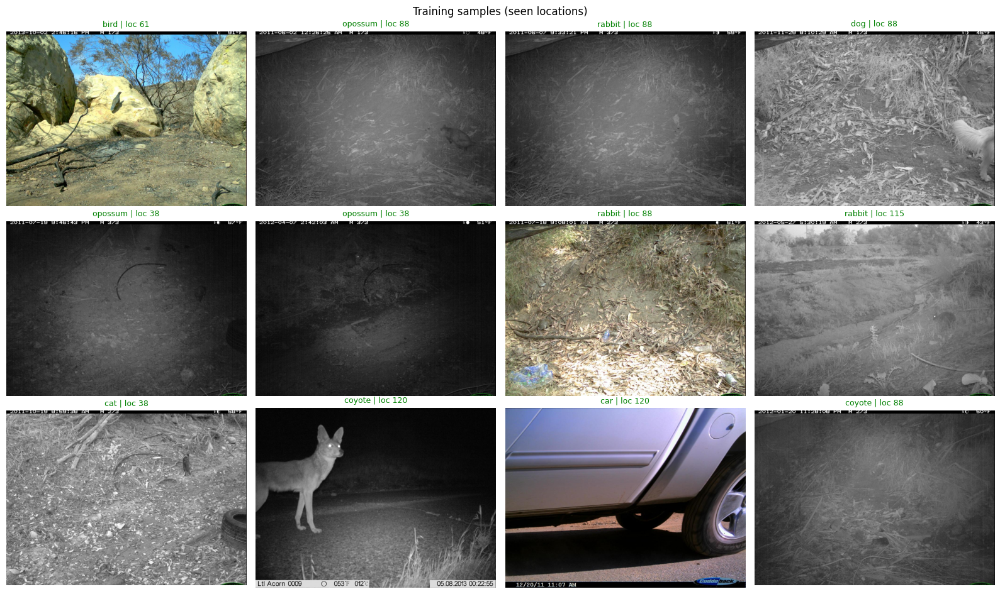

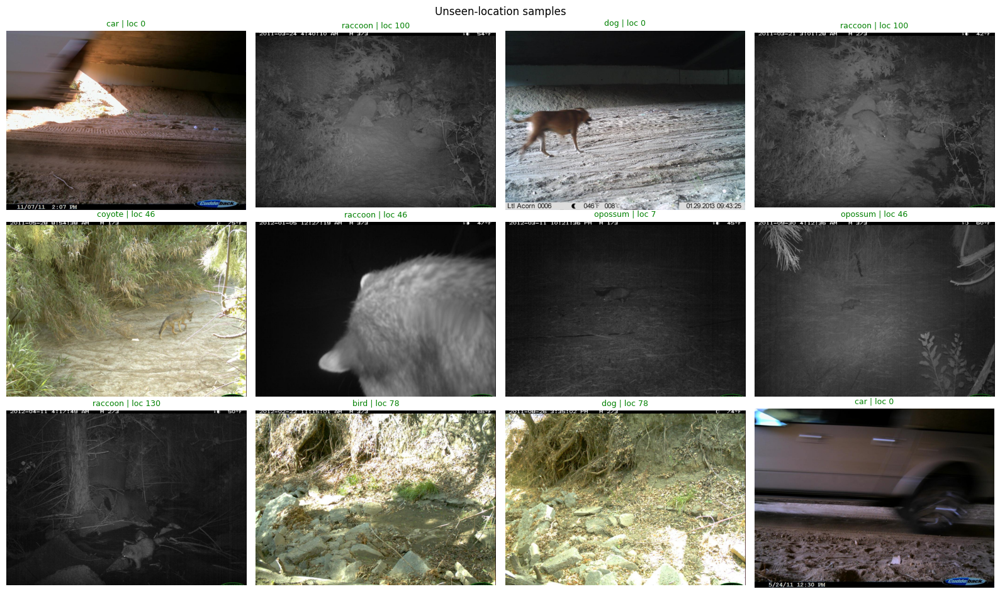

In [12]:
def show_grid(sub, n=12, title=None, pred_col=None, fname=None):
    sub = sub.sample(min(n, len(sub)), random_state=SEED)
    cols = 4; rws = int(np.ceil(len(sub) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(4 * cols, 3.2 * rws))
    for ax, (_, r) in zip(np.ravel(axes), sub.iterrows()):
        ax.imshow(Image.open(os.path.join(IMG_DIR, r.file)).convert('RGB'))
        t = f'{r.label} | loc {r.location}'
        if pred_col: t = f'true: {r.label}\npred: {r[pred_col]} ({r.get("conf", 0):.2f})'
        ax.set_title(t, fontsize=9, color='green' if not pred_col or r.label == r[pred_col] else 'red'); ax.axis('off')
    for ax in np.ravel(axes)[len(sub):]: ax.axis('off')
    if title: fig.suptitle(title)
    plt.tight_layout()
    if fname: plt.savefig(f'{OUT_DIR}/{fname}', dpi=150)
    plt.show()
show_grid(df[df.split == 'train'], title='Training samples (seen locations)', fname='samples_train.png')
show_grid(df[df.split == 'trans_test'], title='Unseen-location samples', fname='samples_trans.png')

In [13]:
# Night-time (infrared) images are greyscale: R, G and B channels are almost identical.
def is_night(path, thresh=2.0):
    a = np.asarray(Image.open(path).convert('RGB').resize((64, 64)), dtype=np.float32)
    return float(np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()) < thresh
test_mask = df.split.isin(['cis_test', 'trans_test'])
night = {f: is_night(os.path.join(IMG_DIR, f)) for f in df.loc[test_mask, 'file']}   # test images only (~40k, a few minutes)
df['night'] = df.file.map(night)
print(df[test_mask].groupby('split').night.mean().rename('share of night images'))

split
cis_test      0.620082
trans_test    0.716435
Name: share of night images, dtype: object


## 5. Pre-processing and data loaders
* Resize to 224×224 (both models were pretrained at this size).
* Normalise with each checkpoint's own statistics (ImageNet for ResNet-50, 0.5/0.5 for the in21k ViT).
* Training augmentation: random resized crop, horizontal flip, colour jitter, and **random greyscale** so day images also teach the model about infrared night shots.
* Class imbalance: class-weighted cross-entropy (weights ∝ 1/√frequency).

In [14]:
NORM = {'resnet50': ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        'vit':      ([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])}
def make_tf(model_name, train):
    mean, std = NORM[model_name]
    if train:
        return T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)), T.RandomHorizontalFlip(),
                          T.ColorJitter(0.3, 0.3, 0.2), T.RandomGrayscale(0.2),
                          T.ToTensor(), T.Normalize(mean, std)])
    return T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(mean, std)])

class CCTDataset(Dataset):
    def __init__(self, frame, tf): self.f, self.tf = frame.reset_index(drop=True), tf
    def __len__(self): return len(self.f)
    def __getitem__(self, i):
        r = self.f.iloc[i]
        return self.tf(Image.open(os.path.join(IMG_DIR, r.file)).convert('RGB')), r.y

def loader(split, model_name, train=False):
    return DataLoader(CCTDataset(df[df.split == split], make_tf(model_name, train)), batch_size=BATCH_SIZE,
                      shuffle=train, num_workers=NUM_WORKERS, pin_memory=(DEVICE == 'cuda'))

freq = df[df.split == 'train'].y.value_counts().reindex(range(len(CLASSES)), fill_value=1).values
CLASS_W = torch.tensor((1 / np.sqrt(freq)) / (1 / np.sqrt(freq)).mean(), dtype=torch.float32)
pd.Series(CLASS_W.numpy(), index=CLASSES).round(2).to_frame('loss weight').T

,bird,bobcat,car,cat,coyote,deer,dog,opossum,rabbit,raccoon,rodent,skunk,squirrel
loss weight,1.02,0.8,0.87,0.62,0.6,3.46,0.78,0.43,0.45,0.7,1.16,1.48,0.63


## 6. Training and evaluation helpers

In [15]:
def logits_of(model, x):
    out = model(x)
    return out.logits if hasattr(out, 'logits') else out

@torch.no_grad()
def predict(model, dl):
    model.eval(); P = []
    for x, _ in dl:
        with torch.autocast(DEVICE, enabled=DEVICE == 'cuda'):
            P.append(logits_of(model, x.to(DEVICE)).float().softmax(-1).cpu())
    return torch.cat(P).numpy()

def metrics(y, p):
    # Macro F1 over the classes present in this test set (deer has no trans_test images; counting it as F1 = 0 would deflate scores)
    return {'accuracy': accuracy_score(y, p), 'macro_f1': f1_score(y, p, average='macro', labels=np.unique(y), zero_division=0)}

def train_model(model, name):
    set_seed()
    model.to(DEVICE)
    tr, va = loader('train', name, train=True), loader('cis_val', name)
    yv = df[df.split == 'cis_val'].y.values
    epochs = 1 if SMOKE_TEST else EPOCHS[name]
    opt = torch.optim.AdamW(model.parameters(), lr=LR[name], weight_decay=WEIGHT_DECAY)
    sched = get_cosine_schedule_with_warmup(opt, int(0.1 * epochs * len(tr)), epochs * len(tr))
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')
    lossf = nn.CrossEntropyLoss(weight=CLASS_W.to(DEVICE), label_smoothing=0.1)
    hist, best = [], -1
    for ep in range(epochs):
        model.train(); t0, tot, n = time.time(), 0.0, 0
        for x, y in tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE, enabled=DEVICE == 'cuda'):
                loss = lossf(logits_of(model, x), y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y)
        m = metrics(yv, predict(model, va).argmax(1))
        hist.append({'epoch': ep + 1, 'train_loss': tot / n, **{f'val_{k}': v for k, v in m.items()}, 'minutes': (time.time() - t0) / 60})
        print(hist[-1])
        if m['macro_f1'] > best:
            best = m['macro_f1']; torch.save(model.state_dict(), f'{OUT_DIR}/{name}_best.pt')
    model.load_state_dict(torch.load(f'{OUT_DIR}/{name}_best.pt', map_location=DEVICE))
    pd.DataFrame(hist).to_csv(f'{OUT_DIR}/{name}_history.csv', index=False)
    return model, pd.DataFrame(hist)

RESULTS = {}   # model name -> {split: probabilities}
def evaluate(name, model=None, probs_fn=None):
    RESULTS[name] = {}
    for split in ['cis_test', 'trans_test']:
        probs = probs_fn(split) if probs_fn else predict(model, loader(split, name))
        RESULTS[name][split] = probs
        np.save(f'{OUT_DIR}/{name}_{split}_probs.npy', probs)
        print(name, split, {k: round(v, 4) for k, v in metrics(df[df.split == split].y.values, probs.argmax(1)).items()})

## 7. Experiment 1: ResNet-50 baseline (CNN)

In [16]:
resnet = torchvision.models.resnet50(weights='IMAGENET1K_V2')
resnet.fc = nn.Linear(resnet.fc.in_features, len(CLASSES))
resnet, hist_resnet = train_model(resnet, 'resnet50')
evaluate('resnet50', resnet)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


{'epoch': 1, 'train_loss': 1.8063580499897858, 'val_accuracy': 0.7138263665594855, 'val_macro_f1': 0.7116949438013774, 'minutes': 3.1856202602386476}
{'epoch': 2, 'train_loss': 1.2008376551054838, 'val_accuracy': 0.787379421221865, 'val_macro_f1': 0.7752944084995025, 'minutes': 2.9036213874816896}
{'epoch': 3, 'train_loss': 1.0780358025604662, 'val_accuracy': 0.8110932475884244, 'val_macro_f1': 0.7916546860624425, 'minutes': 2.852388830979665}
{'epoch': 4, 'train_loss': 1.0086675731940995, 'val_accuracy': 0.8287781350482315, 'val_macro_f1': 0.8366303532981727, 'minutes': 2.809760121504466}
{'epoch': 5, 'train_loss': 0.9550190591657156, 'val_accuracy': 0.8573151125401929, 'val_macro_f1': 0.8567617057728311, 'minutes': 2.8432089646657306}
{'epoch': 6, 'train_loss': 0.9065650993690373, 'val_accuracy': 0.860128617363344, 'val_macro_f1': 0.8544979621351467, 'minutes': 2.8516821384429933}
{'epoch': 7, 'train_loss': 0.8746104972421339, 'val_accuracy': 0.8721864951768489, 'val_macro_f1': 0.870

## 8. Experiment 2: ViT-B/16 fine-tuned (main model)
ViT-Base, 16×16 patches (196 patch tokens + [CLS]), pretrained on ImageNet-21k. The classification head is replaced with a new 13-way head and all weights are fine-tuned. `attn_implementation='eager'` lets us read attention maps later.

In [17]:
vit = ViTForImageClassification.from_pretrained(
    VIT_CKPT, num_labels=len(CLASSES), id2label=dict(enumerate(CLASSES)), label2id=C2I,
    attn_implementation='eager')
print(f'{sum(p.numel() for p in vit.parameters()) / 1e6:.1f}M parameters')
vit, hist_vit = train_model(vit, 'vit')
evaluate('vit', vit)

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


85.8M parameters
{'epoch': 1, 'train_loss': 2.3390181140509396, 'val_accuracy': 0.6382636655948553, 'val_macro_f1': 0.5470658631920757, 'minutes': 3.479348866144816}
{'epoch': 2, 'train_loss': 1.5215418440567583, 'val_accuracy': 0.7447749196141479, 'val_macro_f1': 0.7392021318136487, 'minutes': 3.3660358428955077}
{'epoch': 3, 'train_loss': 1.2382218666294333, 'val_accuracy': 0.7861736334405145, 'val_macro_f1': 0.7814283106134258, 'minutes': 3.35464696486791}
{'epoch': 4, 'train_loss': 1.1165021529735182, 'val_accuracy': 0.819935691318328, 'val_macro_f1': 0.8162779628673918, 'minutes': 3.370561897754669}
{'epoch': 5, 'train_loss': 1.0518411876074336, 'val_accuracy': 0.8279742765273312, 'val_macro_f1': 0.8255015416368262, 'minutes': 3.353561528523763}
{'epoch': 6, 'train_loss': 0.9943342981635775, 'val_accuracy': 0.8340032154340836, 'val_macro_f1': 0.8354618492927113, 'minutes': 3.386832276980082}
{'epoch': 7, 'train_loss': 0.9628827707738252, 'val_accuracy': 0.8291800643086816, 'val_ma

## 9. Experiment 3: CLIP zero-shot (secondary reference)
No training: each class becomes a text prompt and the image is assigned to the most similar prompt. Several prompt templates are averaged (prompt ensembling, Radford et al. 2021).

In [19]:
clip = CLIPModel.from_pretrained(CLIP_CKPT).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_CKPT)
TEMPLATES = ['a camera trap photo of a {}.', 'a trail camera photo of a {} at night.',
             'a blurry photo of a {} in the wild.', 'a photo of a {}.']
NAMES = {'car': 'car', 'rodent': 'small rodent', 'bird': 'bird'}  # optional nicer prompt names

def as_features(o):
    # transformers 4.x returns a tensor; 5.x may return an output object holding the projected features
    return o if torch.is_tensor(o) else o.pooler_output

with torch.no_grad():
    T_emb = []
    for c in CLASSES:
        tok = clip_proc(text=[t.format(NAMES.get(c, c)) for t in TEMPLATES], return_tensors='pt', padding=True).to(DEVICE)
        e = as_features(clip.get_text_features(**tok)); e = e / e.norm(dim=-1, keepdim=True)
        T_emb.append(e.mean(0))
    T_emb = torch.stack(T_emb); T_emb = T_emb / T_emb.norm(dim=-1, keepdim=True)

@torch.no_grad()
def clip_probs(split):
    files = df[df.split == split].file.tolist(); P = []
    for i in range(0, len(files), BATCH_SIZE):
        ims = [Image.open(os.path.join(IMG_DIR, f)).convert('RGB') for f in files[i:i + BATCH_SIZE]]
        x = clip_proc(images=ims, return_tensors='pt')['pixel_values'].to(DEVICE)
        e = as_features(clip.get_image_features(pixel_values=x)); e = e / e.norm(dim=-1, keepdim=True)
        P.append((100 * e @ T_emb.T).softmax(-1).cpu())
    return torch.cat(P).numpy()
evaluate('clip_zeroshot', probs_fn=clip_probs)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

clip_zeroshot cis_test {'accuracy': 0.3156, 'macro_f1': 0.3301}
clip_zeroshot trans_test {'accuracy': 0.3621, 'macro_f1': 0.3162}


## 10. Optional control: ResNet-50 pretrained on ImageNet-21k
The proposal notes a confound: the ViT was pretrained on ImageNet-21k (14M images) while the standard ResNet-50 saw ImageNet-1k (1.3M). BiT-M ResNet-50 (Kolesnikov et al., 2020) is pretrained on ImageNet-21k, so comparing it with the ViT isolates architecture from pretraining scale. Set `RUN_BIT_CONTROL = True` if you have GPU time left.

In [20]:
if RUN_BIT_CONTROL:
    import timm
    NORM['bit'] = ([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]); EPOCHS['bit'] = EPOCHS['resnet50']; LR['bit'] = LR['resnet50']
    bit = timm.create_model('resnetv2_50x1_bit.goog_in21k', pretrained=True, num_classes=len(CLASSES))
    bit, hist_bit = train_model(bit, 'bit')
    evaluate('bit', bit)
else:
    print('Skipped (RUN_BIT_CONTROL = False)')

Skipped (RUN_BIT_CONTROL = False)


## 11. Results: seen vs unseen locations

,model,test set,accuracy,macro_f1
0,resnet50,seen (cis),0.765,0.723
1,resnet50,unseen (trans),0.579,0.467
2,vit,seen (cis),0.682,0.663
3,vit,unseen (trans),0.488,0.404
4,clip_zeroshot,seen (cis),0.316,0.330
5,clip_zeroshot,unseen (trans),0.362,0.316


test set,seen (cis),unseen (trans),relative gap
model,,,
clip_zeroshot,0.330,0.316,0.042
resnet50,0.723,0.467,0.354
vit,0.663,0.404,0.391


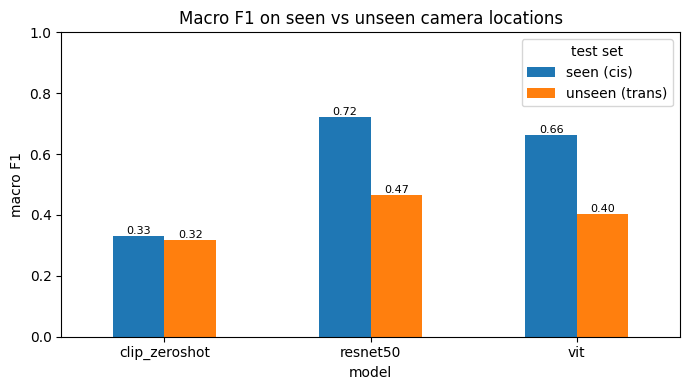

In [21]:
# If you ran experiments in separate sessions, reload saved probabilities instead of re-running.
for name in ['resnet50', 'vit', 'clip_zeroshot', 'bit']:
    if name not in RESULTS and os.path.exists(f'{OUT_DIR}/{name}_cis_test_probs.npy'):
        RESULTS[name] = {s: np.load(f'{OUT_DIR}/{name}_{s}_probs.npy') for s in ['cis_test', 'trans_test']}

res = []
for name, d in RESULTS.items():
    for split, probs in d.items():
        res.append({'model': name, 'test set': 'seen (cis)' if split == 'cis_test' else 'unseen (trans)',
                    **metrics(df[df.split == split].y.values, probs.argmax(1))})
res = pd.DataFrame(res); res.to_csv(f'{OUT_DIR}/results.csv', index=False)
table = res.pivot(index='model', columns='test set', values='macro_f1')
table['relative gap'] = (table['seen (cis)'] - table['unseen (trans)']) / table['seen (cis)']
display(res.round(3)); display(table.round(3))

ax = res.pivot(index='model', columns='test set', values='macro_f1').plot.bar(figsize=(7, 4), rot=0)
ax.set_ylabel('macro F1'); ax.set_title('Macro F1 on seen vs unseen camera locations'); ax.set_ylim(0, 1)
for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/seen_vs_unseen.png', dpi=150); plt.show()

### H1: is the ViT's relative generalisation gap smaller than the ResNet-50's?
Paired bootstrap: each resample draws `cis_test` and `trans_test` images with replacement (the same draw for both models), recomputes both relative gaps, and records the difference **ResNet gap − ViT gap**. If the 95% interval lies entirely above 0, H1 is supported; if it contains 0, H0 cannot be rejected.

In [22]:
def rel_gap(y_c, p_c, y_t, p_t):
    fc = metrics(y_c, p_c)['macro_f1']; ft = metrics(y_t, p_t)['macro_f1']
    return (fc - ft) / fc if fc > 0 else np.nan

def bootstrap_gap_diff(a, b, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    yc, yt = df[df.split == 'cis_test'].y.values, df[df.split == 'trans_test'].y.values
    pa = {s: RESULTS[a][s].argmax(1) for s in ['cis_test', 'trans_test']}
    pb = {s: RESULTS[b][s].argmax(1) for s in ['cis_test', 'trans_test']}
    obs = rel_gap(yc, pa['cis_test'], yt, pa['trans_test']) - rel_gap(yc, pb['cis_test'], yt, pb['trans_test'])
    diffs = []
    for _ in range(1 if SMOKE_TEST else n_boot):
        ic, it = rng.integers(0, len(yc), len(yc)), rng.integers(0, len(yt), len(yt))
        diffs.append(rel_gap(yc[ic], pa['cis_test'][ic], yt[it], pa['trans_test'][it]) -
                     rel_gap(yc[ic], pb['cis_test'][ic], yt[it], pb['trans_test'][it]))
    lo, hi = np.nanpercentile(diffs, [2.5, 97.5])
    return obs, lo, hi

h1_rows = []
for ref in ['resnet50', 'bit']:
    if ref in RESULTS and 'vit' in RESULTS:
        obs, lo, hi = bootstrap_gap_diff(ref, 'vit')
        h1_rows.append({'comparison': f'{ref} gap - vit gap', 'difference': obs, 'ci_low': lo, 'ci_high': hi,
                        'H1 supported (CI > 0)': lo > 0})
h1_table = pd.DataFrame(h1_rows); h1_table.to_csv(f'{OUT_DIR}/h1_bootstrap.csv', index=False)
display(h1_table.round(3))

,comparison,difference,ci_low,ci_high,H1 supported (CI > 0)
0,resnet50 gap - vit gap,-0.037,-0.051,-0.022,False


### Extra metrics: macro precision / recall, balanced accuracy, top-3, size and speed
Computed from the saved predictions (no retraining). Inference speed is measured on 512 `trans_test` images with the models still in memory.

In [31]:
from sklearn.metrics import precision_score, recall_score, balanced_accuracy_score, top_k_accuracy_score
extra = []
for name, d in RESULTS.items():
    for split, probs in d.items():
        y, p = df[df.split == split].y.values, probs.argmax(1); labs = np.unique(y)
        extra.append({'model': name, 'test set': split,
                      'macro_precision': precision_score(y, p, average='macro', labels=labs, zero_division=0),
                      'macro_recall': recall_score(y, p, average='macro', labels=labs, zero_division=0),
                      'balanced_accuracy': balanced_accuracy_score(y, p),
                      'top3_accuracy': top_k_accuracy_score(y, probs, k=3, labels=range(len(CLASSES)))})
extra = pd.DataFrame(extra); extra.to_csv(f'{OUT_DIR}/extra_metrics.csv', index=False); display(extra.round(3))

@torch.no_grad()
def images_per_second(model, name, n=512):
    model.eval(); dl = DataLoader(CCTDataset(df[df.split == 'trans_test'].head(n), make_tf(name, False)), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    xs = [x.to(DEVICE) for x, _ in dl]; logits_of(model, xs[0])          # warm-up
    if DEVICE == 'cuda': torch.cuda.synchronize()
    t = time.time()
    for x in xs:
        with torch.autocast(DEVICE, enabled=DEVICE == 'cuda'): logits_of(model, x)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    return sum(len(x) for x in xs) / (time.time() - t)

eff = []
for name, model in [('resnet50', globals().get('resnet')), ('vit', globals().get('vit')), ('bit', globals().get('bit'))]:
    if model is None: continue
    h = pd.read_csv(f'{OUT_DIR}/{name}_history.csv')
    eff.append({'model': name, 'params_M': sum(p.numel() for p in model.parameters()) / 1e6,
                'train_minutes': h.minutes.sum(), 'best_epoch': int(h.val_macro_f1.idxmax()) + 1,
                'inference_img_per_s': images_per_second(model, name)})
eff = pd.DataFrame(eff); eff.to_csv(f'{OUT_DIR}/efficiency.csv', index=False); display(eff.round(2))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,model,test set,macro_precision,macro_recall,balanced_accuracy,top3_accuracy
0,resnet50,cis_test,0.738,0.724,0.724,0.897
1,resnet50,trans_test,0.466,0.510,0.510,0.753
2,vit,cis_test,0.670,0.698,0.698,0.869
3,vit,trans_test,0.403,0.436,0.436,0.691
4,clip_zeroshot,cis_test,0.494,0.362,0.362,0.585
5,clip_zeroshot,trans_test,0.436,0.326,0.326,0.637


,model,params_M,train_minutes,best_epoch,inference_img_per_s
0,resnet50,23.53,28.75,9,864.65
1,vit,85.81,33.80,8,327.42


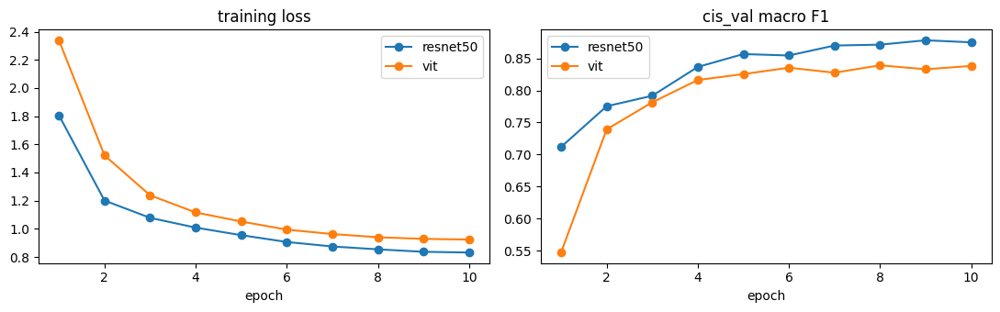

In [23]:
# Training curves for the fine-tuned models
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name in ['resnet50', 'vit', 'bit']:
    p = f'{OUT_DIR}/{name}_history.csv'
    if os.path.exists(p):
        h = pd.read_csv(p)
        axes[0].plot(h.epoch, h.train_loss, marker='o', label=name)
        axes[1].plot(h.epoch, h.val_macro_f1, marker='o', label=name)
axes[0].set_title('training loss'); axes[1].set_title('cis_val macro F1')
for a in axes: a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/training_curves.png', dpi=150); plt.show()

## 12. Bias analysis: per class, per location, day vs night

In [24]:
MAIN = 'vit'
for split in ['cis_test', 'trans_test']:
    sub = df[df.split == split]
    print(f'--- {MAIN} on {split} ---')
    print(classification_report(sub.y, RESULTS[MAIN][split].argmax(1), labels=range(len(CLASSES)),
                                target_names=CLASSES, zero_division=0, digits=3))

--- vit on cis_test ---
              precision    recall  f1-score   support

        bird      0.532     0.604     0.566       573
      bobcat      0.541     0.806     0.647       897
         car      0.990     1.000     0.995       791
         cat      0.708     0.674     0.691      1632
      coyote      0.779     0.685     0.729      1326
        deer      0.819     0.809     0.814       162
         dog      0.781     0.511     0.618       845
     opossum      0.875     0.679     0.765      4524
      rabbit      0.651     0.617     0.634      1757
     raccoon      0.394     0.782     0.524      1047
      rodent      0.749     0.575     0.650       233
       skunk      0.383     0.928     0.542       194
    squirrel      0.509     0.404     0.450       659

    accuracy                          0.682     14640
   macro avg      0.670     0.698     0.663     14640
weighted avg      0.728     0.682     0.691     14640

--- vit on trans_test ---
              precision    re

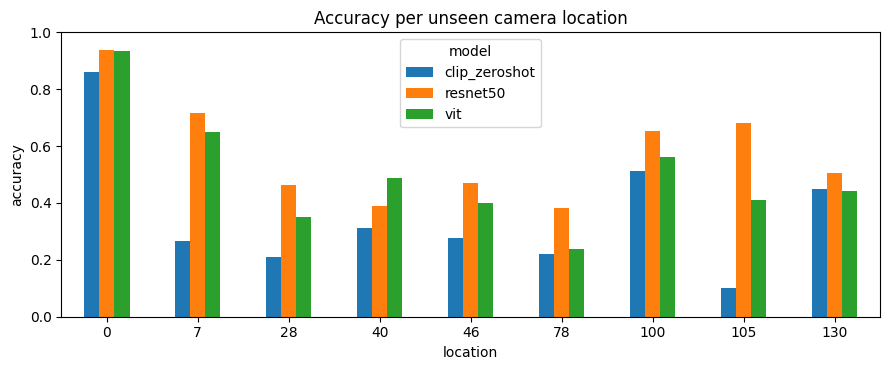

split         cis_test        trans_test       
location           day  night        day  night
model                                          
clip_zeroshot    0.415  0.255      0.448  0.328
resnet50         0.722  0.791      0.560  0.587
vit              0.680  0.683      0.507  0.481

In [25]:
rows = []
for name, d in RESULTS.items():
    for split, probs in d.items():
        sub = df[df.split == split].assign(pred=probs.argmax(1))
        for loc, g in sub.groupby('location'):
            rows.append({'model': name, 'split': split, 'location': loc, 'n': len(g), 'accuracy': (g.y == g.pred).mean()})
        for night, g in sub.groupby('night'):
            rows.append({'model': name, 'split': split, 'location': 'night' if night else 'day', 'n': len(g), 'accuracy': (g.y == g.pred).mean()})
br = pd.DataFrame(rows); br.to_csv(f'{OUT_DIR}/breakdowns.csv', index=False)

loc = br[(br.split == 'trans_test') & ~br.location.isin(['day', 'night'])]
ax = loc.pivot(index='location', columns='model', values='accuracy').plot.bar(figsize=(9, 3.8), rot=0)
ax.set_title('Accuracy per unseen camera location'); ax.set_ylabel('accuracy'); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/per_location.png', dpi=150); plt.show()
display(br[br.location.isin(['day', 'night'])].pivot_table(index='model', columns=['split', 'location'], values='accuracy').round(3))

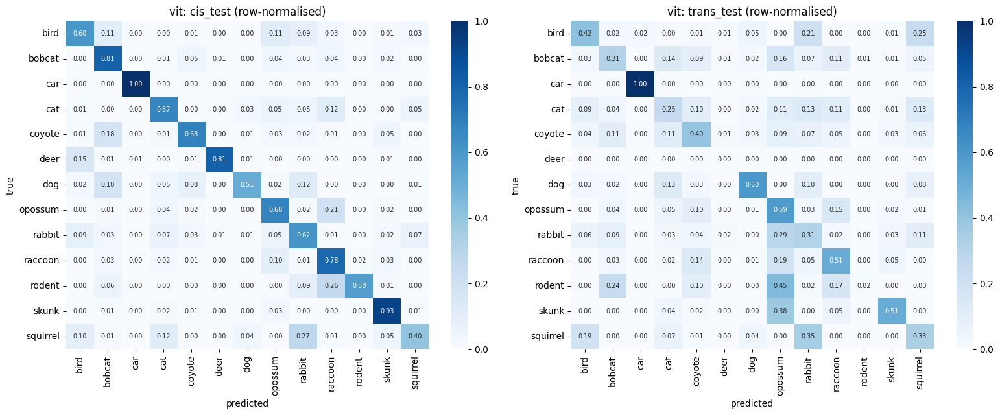

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, split in zip(axes, ['cis_test', 'trans_test']):
    y = df[df.split == split].y.values
    cm = confusion_matrix(y, RESULTS[MAIN][split].argmax(1), labels=range(len(CLASSES)), normalize='true')
    sns.heatmap(cm, ax=ax, cmap='Blues', vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, annot=True, fmt='.2f', annot_kws={'size': 7})
    ax.set_title(f'{MAIN}: {split} (row-normalised)'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_{MAIN}.png', dpi=150); plt.show()

## 13. Explainability and H2: what does the ViT look at?
**Attention rollout** (Abnar & Zuidema, 2020) multiplies the attention matrices through all 12 layers to estimate how much each patch contributes to the [CLS] token. If attention on errors falls on background rather than the animal, that supports the background-shortcut explanation of the location gap.

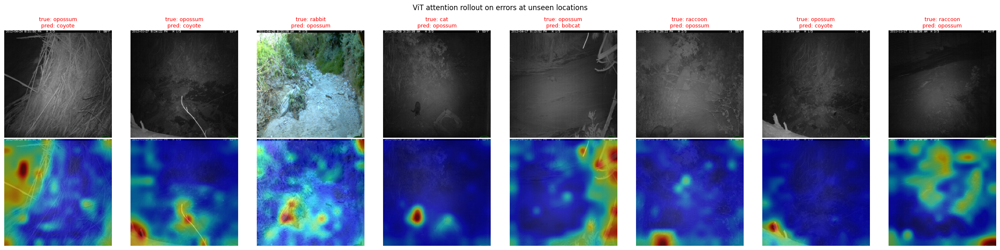

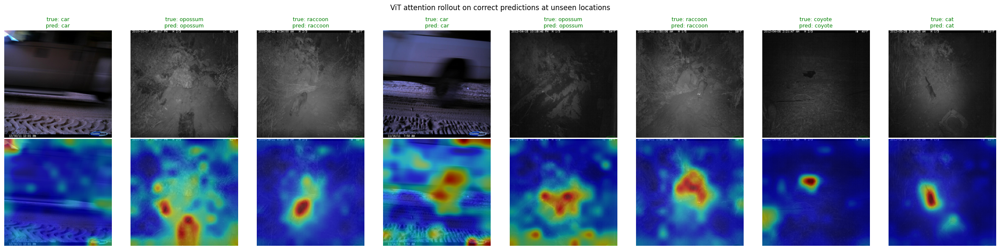

In [27]:
@torch.no_grad()
def attention_rollout(model, x):
    out = model(x, output_attentions=True)
    A = torch.eye(out.attentions[0].shape[-1], device=x.device)
    for att in out.attentions:
        a = att[0].mean(0); a = a + torch.eye(a.shape[-1], device=x.device); a = a / a.sum(-1, keepdim=True)
        A = a @ A
    m = A[0, 1:]; s = int(m.numel() ** 0.5)
    return (m / m.max()).reshape(s, s).cpu().numpy()

def show_attention(sub, n=8, fname=None, title=''):
    vit.eval(); tf = make_tf('vit', False)
    sub = sub.head(n); fig, axes = plt.subplots(2, len(sub), figsize=(3 * len(sub), 6))
    axes = np.array(axes).reshape(2, -1)
    for j, (_, r) in enumerate(sub.iterrows()):
        im = Image.open(os.path.join(IMG_DIR, r.file)).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        m = attention_rollout(vit, tf(im).unsqueeze(0).to(DEVICE))
        axes[0, j].imshow(im); axes[0, j].set_title(f'true: {r.label}\npred: {r.pred}', fontsize=9,
                                                     color='green' if r.label == r.pred else 'red')
        axes[1, j].imshow(im); axes[1, j].imshow(np.array(Image.fromarray(np.uint8(m * 255)).resize((IMG_SIZE, IMG_SIZE))), alpha=0.55, cmap='jet')
        axes[0, j].axis('off'); axes[1, j].axis('off')
    fig.suptitle(title); plt.tight_layout()
    if fname: plt.savefig(f'{OUT_DIR}/{fname}', dpi=150)
    plt.show()

tt = df[df.split == 'trans_test'].assign(pred=[CLASSES[i] for i in RESULTS['vit']['trans_test'].argmax(1)],
                                         conf=RESULTS['vit']['trans_test'].max(1))
show_attention(tt[tt.label != tt.pred].sample(min(8, (tt.label != tt.pred).sum()), random_state=SEED),
               fname='attention_errors.png', title='ViT attention rollout on errors at unseen locations')
show_attention(tt[tt.label == tt.pred].sample(min(8, (tt.label == tt.pred).sum()), random_state=SEED),
               fname='attention_correct.png', title='ViT attention rollout on correct predictions at unseen locations')

### H2: is attention outside the animal associated with errors?
For each unseen-location image with an annotated bounding box, compute the share of attention-rollout mass that falls inside the box (boxes rescaled from original resolution to the 224×224 input). Compare correct vs misclassified images with a one-sided Mann-Whitney U test (alternative: misclassified < correct). For reference, the box's share of the image area is also recorded, since a large box captures more attention by chance.

,attn_in_box,box_area,attn_density
correct,,,
misclassified,0.064,0.046,1.236
correct,0.090,0.061,1.328


,measure,n_correct,n_wrong,median_correct,median_wrong,U,p_one_sided,supported (p < 0.05)
0,attn_in_box,1635,1365,0.0904,0.0637,828089.0,0.0,True
1,attn_density,1635,1365,1.3278,1.2356,949772.0,0.0,True


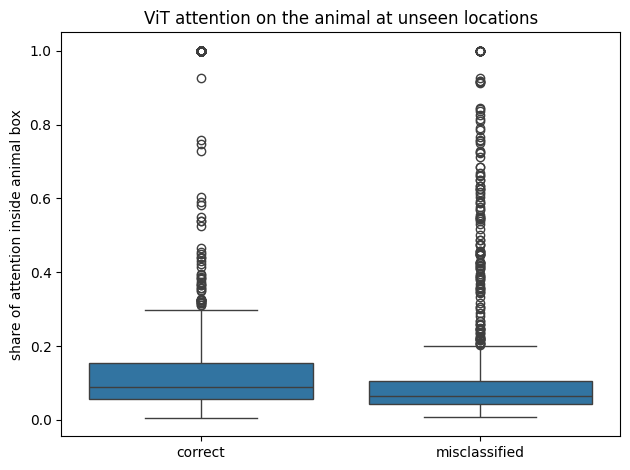

In [28]:
@torch.no_grad()
def rollout_batch(model, x):
    atts = model(x, output_attentions=True).attentions
    n = atts[0].shape[-1]; I = torch.eye(n, device=x.device)
    A = I.expand(x.shape[0], n, n)
    for att in atts:
        a = att.mean(1) + I; a = a / a.sum(-1, keepdim=True); A = a @ A
    m = A[:, 0, 1:]; s = int(m.shape[-1] ** 0.5)
    return (m / m.sum(-1, keepdim=True)).reshape(-1, s, s).cpu().numpy()

def box_mask(boxes, ow, oh, grid):
    M = np.zeros((grid, grid), bool)
    for x, y, w, h in boxes:
        c0, c1 = int(np.floor(x / ow * grid)), int(np.ceil((x + w) / ow * grid))
        r0, r1 = int(np.floor(y / oh * grid)), int(np.ceil((y + h) / oh * grid))
        M[max(r0, 0):min(r1, grid), max(c0, 0):min(c1, grid)] = True
    return M

h2_df = tt[tt.boxes.map(len) > 0]
h2_df = h2_df.sample(min(H2_MAX_IMAGES, len(h2_df)), random_state=SEED)
tf = make_tf('vit', False); fr, area = [], []
for i in range(0, len(h2_df), 32):
    chunk = h2_df.iloc[i:i + 32]
    x = torch.stack([tf(Image.open(os.path.join(IMG_DIR, f)).convert('RGB')) for f in chunk.file]).to(DEVICE)
    for m, (_, r) in zip(rollout_batch(vit, x), chunk.iterrows()):
        M = box_mask(r.boxes, r.orig_w, r.orig_h, m.shape[0])
        fr.append(float(m[M].sum())); area.append(float(M.mean()))
h2_df = h2_df.assign(attn_in_box=fr, box_area=area, correct=h2_df.label == h2_df.pred)
# Control for box size: density > 1 means the box gets more attention than its share of the image would by chance
h2_df['attn_density'] = h2_df.attn_in_box / h2_df.box_area.clip(lower=1e-6)
h2_df[['file', 'label', 'pred', 'correct', 'attn_in_box', 'box_area', 'attn_density', 'location']].to_csv(f'{OUT_DIR}/h2_attention.csv', index=False)

ok, bad = h2_df[h2_df.correct].attn_in_box, h2_df[~h2_df.correct].attn_in_box
summary = h2_df.groupby('correct')[['attn_in_box', 'box_area', 'attn_density']].median().rename(index={True: 'correct', False: 'misclassified'})
display(summary.round(3))
tests = []
for col in ['attn_in_box', 'attn_density']:   # raw share (H2 as stated) and the box-size-controlled version
    ok_c, bad_c = h2_df[h2_df.correct][col], h2_df[~h2_df.correct][col]
    if len(ok_c) and len(bad_c):
        u, pval = mannwhitneyu(bad_c, ok_c, alternative='less')
        tests.append({'measure': col, 'n_correct': len(ok_c), 'n_wrong': len(bad_c), 'median_correct': ok_c.median(),
                      'median_wrong': bad_c.median(), 'U': u, 'p_one_sided': pval, 'supported (p < 0.05)': pval < 0.05})
h2_tests = pd.DataFrame(tests); h2_tests.to_csv(f'{OUT_DIR}/h2_test.csv', index=False)
display(h2_tests.round(4))

ax = sns.boxplot(data=h2_df.assign(outcome=h2_df.correct.map({True: 'correct', False: 'misclassified'})),
                 x='outcome', y='attn_in_box', order=['correct', 'misclassified'])
ax.set_ylabel('share of attention inside animal box'); ax.set_xlabel('')
ax.set_title('ViT attention on the animal at unseen locations')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/h2_attention_boxplot.png', dpi=150); plt.show()

## 14. Embedding space: does the ViT cluster by species or by location?
t-SNE of the [CLS] embedding. If points group by **location** more than by **species**, the model has partly learned backgrounds.

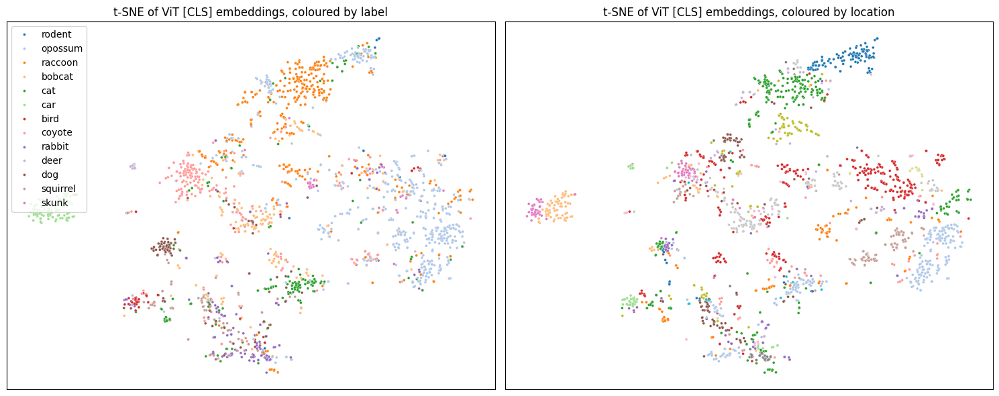

In [29]:
from sklearn.manifold import TSNE
@torch.no_grad()
def cls_embeddings(frame):
    vit.eval(); dl = DataLoader(CCTDataset(frame, make_tf('vit', False)), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS); E = []
    for x, _ in dl:
        E.append(vit.vit(x.to(DEVICE)).last_hidden_state[:, 0].float().cpu())
    return torch.cat(E).numpy()
sample = df[df.split.isin(['cis_test', 'trans_test'])].sample(min(2000, test_mask.sum()), random_state=SEED)
Z = TSNE(n_components=2, perplexity=min(30, len(sample) - 1), random_state=SEED, init='pca').fit_transform(cls_embeddings(sample))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, col in zip(axes, ['label', 'location']):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=sample[col].astype(str).values, s=8, ax=ax, palette='tab20', legend=col == 'label')
    ax.set_title(f't-SNE of ViT [CLS] embeddings, coloured by {col}'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/tsne.png', dpi=150); plt.show()

## 15. Sample predictions

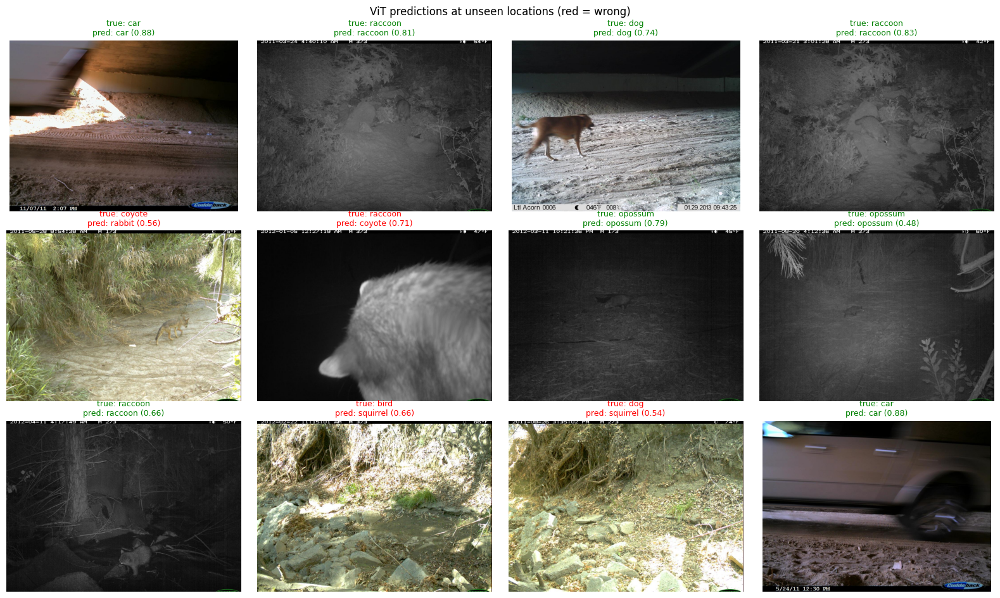

In [30]:
show_grid(tt, n=12, pred_col='pred', title='ViT predictions at unseen locations (red = wrong)', fname='sample_predictions.png')

## 16. Notes for the report
* Results, breakdowns and every figure are saved in `OUT_DIR`; download that folder for the write-up.
* Report the exact configuration: model checkpoints, image size, epochs, learning rates, batch size, augmentation, loss weighting, seed.
* H1 evidence: `results.csv`, `h1_bootstrap.csv`, `seen_vs_unseen.png`. H2 evidence: `h2_test.csv`, `h2_attention_boxplot.png`, `attention_errors.png`.
* Ethics hooks from this notebook: per-class recall on rare classes (skunk, deer, rodent), the seen vs unseen gap, the day vs night gap, and any attention on background or on humans/cars.
* CCT20 is released under the CDLA-Permissive 1.0 licence. Cite Beery, Van Horn & Perona (2018) for the dataset.

## 17. Download all outputs

In [32]:
import shutil
zip_path = shutil.make_archive('/content/cct20_outputs', 'zip', OUT_DIR)
print('Saved', zip_path)
try:
    from google.colab import files; files.download(zip_path)
except ImportError:
    pass

Saved /content/cct20_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>